# Pac-Man com Aprendizagem por Reforço (Q-learning)

O Pac-Man começa em **S**, precisa chegar à cereja **E** e morre se encostar num fantasma **T**. Ele não recebe o mapa pronto: aprende por tentativa e erro.


## 1. Imports

In [14]:
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle, Wedge
from IPython.display import HTML, display

## 2. Labirinto
- `S` entrada 
- `E` saída 
- `#` parede 
- `T` armadilha (o walker morre) 
- `.` caminho livre (com bolinha)

In [15]:
MAZE = [
    "S..#....#...T...",
    ".#.#.T#.#.#.###.",
    ".#...#..#.#...#.",
    ".T##.#.##.###.#.",
    "...#.#.T..#...#.",
    "#T.#T#.####.###.",
    "...T...#....#...",
    ".#T..#.#.##.#.#.",
    ".#.###.#.#T.#.#.",
    ".#.....#.#..#.#.",
    ".####T.#.####.#.",
    ".....T..........",
    ".######.######T.",
    ".#...T..#.....#.",
    ".#.#####.#.##.#.",
    "...T....T#...#.E",
]

N_ROWS, N_COLS = len(MAZE), len(MAZE[0])
ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}   # cima, baixo, esquerda, direita
ACTION_NAME = {0: "↑", 1: "↓", 2: "←", 3: "→"}

def find(char):
    for i, row in enumerate(MAZE):
        if char in row:
            return (i, row.index(char))

START, EXIT = find("S"), find("E")

## 3. Ambiente
Dado um estado e uma ação, `step` devolve o novo estado, a recompensa e se o episódio acabou.
- Passo normal: `-1` (incentiva o caminho mais curto).
- Bateu na borda ou na parede: fica no lugar e leva uma punição pequena.
- Bolinha comida pela 1ª vez no episódio: `PELLET_BONUS` compensa o custo do passo.

In [16]:
PELLET_BONUS = 3   # comer uma bolinha (1ª vez no episódio) compensa o custo do passo


def step(state, action, eaten=None):
    di, dj = ACTIONS[action]
    i, j = state[0] + di, state[1] + dj
    if not (0 <= i < N_ROWS and 0 <= j < N_COLS) or MAZE[i][j] == "#":
        return state, -5, False, "wall"
    cell = MAZE[i][j]
    if cell == "T":
        return (i, j), -100, True, "died"
    if cell == "E":
        return (i, j), +100, True, "exit"
    if eaten is not None and cell == "." and (i, j) not in eaten:
        eaten.add((i, j))
        return (i, j), -1 + PELLET_BONUS, False, "ate"
    return (i, j), -1, False, "moved"      


def draw(path=None, position=None):
    path = set(path or [])
    for i in range(N_ROWS):
        row = ""
        for j in range(N_COLS):
            c = MAZE[i][j]
            if (i, j) == position:
                c = "W"
            elif (i, j) in path and c == ".":
                c = "*"
            row += c + " "
        print(row)
    print()

## 4. Parâmetros do Q-learning
- `alpha` — taxa de aprendizado
- `gamma` — peso do futuro
- `epsilon` — exploração inicial (100% aleatório)
- `epsilon_min` — exploração mínima no fim do treino
- `decay` — quanto o epsilon diminui a cada episódio
- `N_EPISODES` — quantas tentativas o Pac-Man faz
- `MAX_STEPS` — limite de passos por tentativa

In [17]:
alpha = 0.2          
gamma = 0.5          
epsilon = 1.0       
epsilon_min = 0.001  
decay = 0.998       
N_EPISODES = 3000   
MAX_STEPS = 400     
PHASE = 100         
SEED = 42

## 5. Treinamento
`train` roda o Q-learning, imprime um resumo a cada fase e guarda o último caminho de cada fase (usado no vídeo).
`run_greedy` faz o walker andar sozinho, sem exploração.

In [18]:
def run_greedy(Q):
    state, path, actions, eaten = START, [START], [], set()
    for _ in range(MAX_STEPS):
        action = int(np.argmax(Q[state]))
        state, _, done, event = step(state, action, eaten)
        path.append(state); actions.append(action)
        if done:
            return path, event, actions
    return path, "lost", actions


def train(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    Q = np.zeros((N_ROWS, N_COLS, 4))   # valor de cada ação em cada célula
    eps = epsilon
    history, rewards, recorded = [], [], []   # recorded: (título, caminho, resultado) por fase

    for episode in range(1, N_EPISODES + 1):
        state, total, path, result = START, 0, [START], "lost"
        eaten = set()   # bolinhas já comidas neste episódio

        for _ in range(MAX_STEPS):
            # epsilon-greedy: explora ou usa o que já aprendeu
            if random.random() < eps:
                action = random.randint(0, 3)
            else:
                action = int(np.argmax(Q[state]))

            new_state, r, done, event = step(state, action, eaten)
            target = r if done else r + gamma * np.max(Q[new_state])
            Q[state][action] += alpha * (target - Q[state][action])

            state, total = new_state, total + r
            path.append(state)
            if done:
                result = event
                break

        eps = max(epsilon_min, eps * decay)
        history.append(result)
        rewards.append(total)

        if episode % PHASE == 0:
            last = history[-PHASE:]
            title = (f"Fase {episode // PHASE}  (ep. {episode})  |  sucessos {last.count('exit')}/{PHASE}"
                     f"  |  mortes {last.count('died')}/{PHASE}")
            recorded.append((title, path, result))
            print(f"{title}  |  epsilon={eps:.3f}  |  último: {result.upper()} em {len(path) - 1} passos")

    path, result, _ = run_greedy(Q)
    recorded.append(("TESTE FINAL: walker treinado", path, result))
    return Q, history, rewards, recorded


Q, history, rewards, recorded_episodes = train()

first = history.index("exit") + 1 if "exit" in history else None
print(f"\nPrimeiro sucesso no episódio: {first}" + (f"  (fase {-(-first // PHASE)})" if first else ""))

Fase 1  (ep. 100)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.819  |  último: DIED em 23 passos
Fase 2  (ep. 200)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.670  |  último: DIED em 7 passos
Fase 3  (ep. 300)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.548  |  último: DIED em 10 passos
Fase 4  (ep. 400)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.449  |  último: DIED em 7 passos
Fase 5  (ep. 500)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.368  |  último: DIED em 39 passos
Fase 6  (ep. 600)  |  sucessos 1/100  |  mortes 95/100  |  epsilon=0.301  |  último: DIED em 30 passos
Fase 7  (ep. 700)  |  sucessos 0/100  |  mortes 98/100  |  epsilon=0.246  |  último: DIED em 127 passos
Fase 8  (ep. 800)  |  sucessos 1/100  |  mortes 96/100  |  epsilon=0.202  |  último: DIED em 29 passos
Fase 9  (ep. 900)  |  sucessos 38/100  |  mortes 59/100  |  epsilon=0.165  |  último: DIED em 15 passos
Fase 10  (ep. 1000)  |  sucessos 74/100  |  mortes 26/100  |  epsilo

## 6. Resultados

### 6.1 Gráficos de aprendizado
Esquerda: % de sucesso (verde) e de morte (vermelho) nos últimos 50 episódios. Direita: recompensa total de cada episódio.

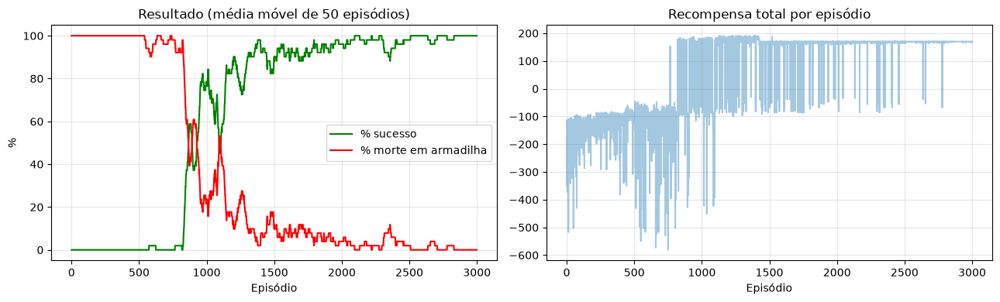

In [19]:
window = 50
rate = [np.mean([h == "exit" for h in history[max(0, k-window):k+1]]) * 100 for k in range(len(history))]
death = [np.mean([h == "died" for h in history[max(0, k-window):k+1]]) * 100 for k in range(len(history))]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(rate, label="% sucesso", color="green")
ax[0].plot(death, label="% morte em armadilha", color="red")
ax[0].set_title(f"Resultado (média móvel de {window} episódios)")
ax[0].set_xlabel("Episódio"); ax[0].set_ylabel("%"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(rewards, alpha=.4)
ax[1].set_title("Recompensa total por episódio")
ax[1].set_xlabel("Episódio"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### 6.2 Teste final
O walker treinado anda sozinho, sem exploração.

In [20]:
path, event, actions = run_greedy(Q)
print("Walker treinado percorrendo o labirinto:\n")
for n, (a, pos) in enumerate(zip(actions, path[1:]), 1):
    print(f"Passo {n:2d}: {ACTION_NAME[a]} -> {pos}")

print()
draw(path, position=path[-1])
if event == "exit":
    print(f"SUCESSO! O walker saiu vivo do labirinto em {len(path) - 1} passos.")
else:
    print(f"Não conseguiu sair (resultado: {event}). Tente aumentar N_EPISODES.")

Walker treinado percorrendo o labirinto:

Passo  1: → -> (0, 1)
Passo  2: → -> (0, 2)
Passo  3: ↓ -> (1, 2)
Passo  4: ↓ -> (2, 2)
Passo  5: → -> (2, 3)
Passo  6: → -> (2, 4)
Passo  7: ↑ -> (1, 4)
Passo  8: ↑ -> (0, 4)
Passo  9: → -> (0, 5)
Passo 10: → -> (0, 6)
Passo 11: → -> (0, 7)
Passo 12: ↓ -> (1, 7)
Passo 13: ↓ -> (2, 7)
Passo 14: ← -> (2, 6)
Passo 15: ↓ -> (3, 6)
Passo 16: ↓ -> (4, 6)
Passo 17: ↓ -> (5, 6)
Passo 18: ↓ -> (6, 6)
Passo 19: ↓ -> (7, 6)
Passo 20: ↓ -> (8, 6)
Passo 21: ↓ -> (9, 6)
Passo 22: ↓ -> (10, 6)
Passo 23: ↓ -> (11, 6)
Passo 24: → -> (11, 7)
Passo 25: → -> (11, 8)
Passo 26: → -> (11, 9)
Passo 27: → -> (11, 10)
Passo 28: → -> (11, 11)
Passo 29: → -> (11, 12)
Passo 30: → -> (11, 13)
Passo 31: → -> (11, 14)
Passo 32: → -> (11, 15)
Passo 33: ↓ -> (12, 15)
Passo 34: ↓ -> (13, 15)
Passo 35: ↓ -> (14, 15)
Passo 36: ↓ -> (15, 15)

S * * # * * * * # . . . T . . . 
. # * # * T # * # . # . # # # . 
. # * * * # * * # . # . . . # . 
. T # # . # * # # . # # # . # . 
. . . # 

### 6.3 Política aprendida
Melhor ação em cada célula.

In [21]:
print("Mapa de decisões aprendidas:\n")
for i in range(N_ROWS):
    row = ""
    for j in range(N_COLS):
        c = MAZE[i][j]
        row += (ACTION_NAME[int(np.argmax(Q[i, j]))] if c in ".S" else c) + " "
    print(row)

Mapa de decisões aprendidas:

→ → ↓ # → → → ↓ # → → ↓ T → ← ← 
↑ # ↓ # ↑ T # ↓ # ↓ # ↑ # # # ↓ 
↑ # → → ↑ # ↓ ← # ↑ # → → ← # ↑ 
↓ T # # ↑ # ↓ # # ↓ # # # ↓ # ↑ 
→ → ↓ # ↑ # ↓ T → ↑ # ↓ → ← # ↓ 
# T ↑ # T # ↓ # # # # ↓ # # # ↓ 
→ ← ↑ T → → ↓ # → → ← ↓ # → → ↓ 
↓ # T → ← # ↓ # ↓ # # ↑ # ↑ # ↓ 
↓ # ↓ # # # ↓ # ↓ # T ↑ # ↑ # ↓ 
↑ # → → → → ↓ # ↑ # → ↑ # ↑ # ↓ 
↓ # # # # T ↓ # ↓ # # # # ↑ # ↓ 
→ → → → ← T → → → → → → → → → ↓ 
↑ # # # # # # ↑ # # # # # # T ↓ 
↓ # ↓ ← ← T → ← # ↑ ↑ ↑ ↑ ↑ # ↓ 
↑ # ↑ # # # # # ↑ # ↑ # # ↑ # ↓ 
→ ← ↑ T ↑ ↑ ↑ ↑ T # ↑ ↑ ↑ # ↑ E 


## 7. Visualização e vídeo

### 7.1 Mapa 2D do cenário

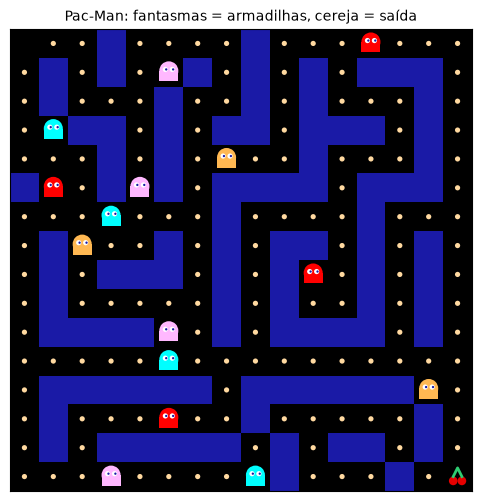

In [22]:
CODE = {".": 0, "#": 1, "T": 0, "S": 0, "E": 0}
COLORS = ListedColormap(["#000000", "#1a1aa6"])
GRID = np.array([[CODE[c] for c in row] for row in MAZE])
GHOST_COLORS = ["#ff0000", "#ffb8ff", "#00ffff", "#ffb852"]   


def draw_ghost(ax, x, y, col):
    ax.add_patch(Circle((x, y - .05), .33, fc=col, ec="none", zorder=3))
    ax.add_patch(Rectangle((x - .33, y - .05), .66, .36, fc=col, ec="none", zorder=3))
    for dx in (-.12, .12):
        ax.add_patch(Circle((x + dx, y - .1), .09, fc="white", ec="none", zorder=4))
        ax.add_patch(Circle((x + dx + .03, y - .1), .04, fc="#1a1aa6", ec="none", zorder=4))


def draw_base(ax):
    ax.set_facecolor("black")
    ax.imshow(GRID, cmap=COLORS, vmin=0, vmax=1)
    k, pellets = 0, {}
    for i in range(N_ROWS):
        for j in range(N_COLS):
            c = MAZE[i][j]
            if c == ".":
                pellets[(i, j)] = Circle((j, i), .09, fc="#ffd9a0", ec="none", zorder=2)
                ax.add_patch(pellets[(i, j)])
            elif c == "T":
                draw_ghost(ax, j, i, GHOST_COLORS[k % 4]); k += 1
            elif c == "E":   # cereja
                for dx in (-.15, .15):
                    ax.add_patch(Circle((j + dx, i + .15), .15, fc="#e60000", ec="none", zorder=3))
                ax.plot([j - .15, j, j + .15], [i, i - .3, i], color="#2ecc71", lw=2, zorder=3)
    ax.set_xticks([]); ax.set_yticks([])
    return pellets


def plot_maze(path=None, title="Labirinto"):
    fig, ax = plt.subplots(figsize=(6, 6))
    draw_base(ax)
    if path:
        ys, xs = zip(*path)
        ax.plot(xs, ys, "-o", color="#f39c12", lw=2, ms=4)
    ax.set_title(title, fontsize=10)
    plt.show()


plot_maze(title="Pac-Man: fantasmas = armadilhas, cereja = saída")

### 7.2 Caminho de cada fase
Os caminhos já foram gravados durante o treinamento (`recorded_episodes`).

In [23]:
for title, path, result in recorded_episodes:
    print(f"{title:70s} -> {result.upper():8s} ({len(path) - 1} passos)")

Fase 1  (ep. 100)  |  sucessos 0/100  |  mortes 100/100                -> DIED     (23 passos)
Fase 2  (ep. 200)  |  sucessos 0/100  |  mortes 100/100                -> DIED     (7 passos)
Fase 3  (ep. 300)  |  sucessos 0/100  |  mortes 100/100                -> DIED     (10 passos)
Fase 4  (ep. 400)  |  sucessos 0/100  |  mortes 100/100                -> DIED     (7 passos)
Fase 5  (ep. 500)  |  sucessos 0/100  |  mortes 100/100                -> DIED     (39 passos)
Fase 6  (ep. 600)  |  sucessos 1/100  |  mortes 95/100                 -> DIED     (30 passos)
Fase 7  (ep. 700)  |  sucessos 0/100  |  mortes 98/100                 -> DIED     (127 passos)
Fase 8  (ep. 800)  |  sucessos 1/100  |  mortes 96/100                 -> DIED     (29 passos)
Fase 9  (ep. 900)  |  sucessos 38/100  |  mortes 59/100                -> DIED     (15 passos)
Fase 10  (ep. 1000)  |  sucessos 74/100  |  mortes 26/100              -> EXIT     (51 passos)
Fase 11  (ep. 1100)  |  sucessos 57/100  |  mortes 

### 7.3 Gerar o vídeo
O Pac-Man anda em cada fase até aprender.

In [24]:
def make_video(recorded, max_steps_per_phase=60, pause=8, fps=6, filename="walker_labirinto"):
    # monta a lista de quadros: (indice_do_episodio, passo)
    frame_list = []
    for k, (_, path, _) in enumerate(recorded):
        n = min(len(path), max_steps_per_phase)
        frame_list += [(k, p) for p in range(n)]
        frame_list += [(k, n - 1)] * pause          # segura a imagem no fim de cada fase

    fig, ax = plt.subplots(figsize=(6.5, 7))
    pellets = draw_base(ax)
    trail, = ax.plot([], [], "-", color="#f39c12", lw=2, alpha=.6)
    # boneco Pac-Man: fatia amarela que abre/fecha a boca e olha para onde anda
    walker = Wedge((0, 0), .4, 30, 330, fc="#f1c40f", ec="black", lw=1.5, zorder=5)
    ax.add_patch(walker)
    title = ax.set_title("", fontsize=10)
    banner = ax.text(N_COLS / 2 - .5, N_ROWS / 2 - .5, "", ha="center", va="center",
                    fontsize=34, weight="bold")

    angle = [0]   # direção atual do Pac-Man (graus)

    def update(q):
        k, p = frame_list[q]
        name, path, result = recorded[k]
        ys, xs = zip(*path[:p + 1])
        trail.set_data(xs, ys)
        visited = set(path[:p + 1])
        for pos, b in pellets.items():
            b.set_visible(pos not in visited)   # bolinha comida some
        if p > 0 and (xs[-1], ys[-1]) != (xs[-2], ys[-2]):
            angle[0] = np.degrees(np.arctan2(ys[-1] - ys[-2], xs[-1] - xs[-2]))
        mouth = 35 if p % 2 == 0 else 5
        walker.set_center((xs[-1], ys[-1]))
        walker.set_theta1(angle[0] + mouth); walker.set_theta2(angle[0] + 360 - mouth)
        title.set_text(f"{name}\npasso {p}")
        is_last = p == min(len(path), max_steps_per_phase) - 1
        if is_last and result == "exit":
            banner.set_text("SAIU VIVO!"); banner.set_color("#27ae60")
        elif is_last and result == "died":
            banner.set_text("MORREU!"); banner.set_color("#c0392b")
        elif is_last:
            banner.set_text("PERDIDO"); banner.set_color("#7f8c8d")
        else:
            banner.set_text("")
        return trail, walker, title, banner

    anim = animation.FuncAnimation(fig, update, frames=len(frame_list), interval=1000 / fps, blit=False)
    plt.close(fig)

    # salva em MP4 (se tiver ffmpeg) ou GIF (sempre funciona)
    if animation.writers.is_available("ffmpeg"):
        anim.save(filename + ".mp4", writer=animation.FFMpegWriter(fps=fps))
        print(f"Vídeo salvo: {filename}.mp4")
    else:
        anim.save(filename + ".gif", writer=animation.PillowWriter(fps=fps))
        print(f"Vídeo salvo: {filename}.gif  (instale ffmpeg para gerar .mp4)")
    return anim


anim = make_video(recorded_episodes)
HTML(anim.to_jshtml())        # player com play/pausa dentro do notebook

Vídeo salvo: walker_labirinto.gif  (instale ffmpeg para gerar .mp4)


Animation size has reached 21020772 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


### 7.4 Caminho final aprendido

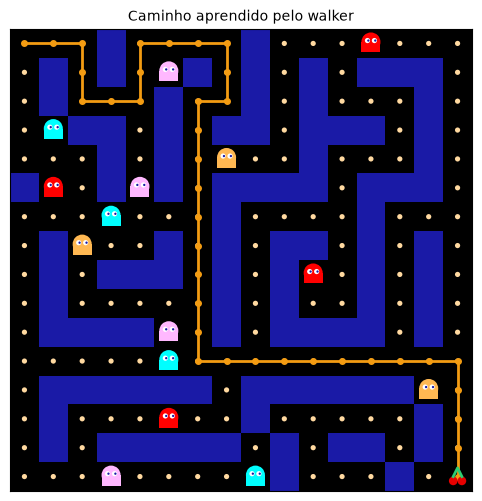

In [25]:
plot_maze(recorded_episodes[-1][1], title="Caminho aprendido pelo walker")